In [1]:
import pandas as pd
import numpy as np
from tqdm import tqdm
import numpy as np
import seaborn as sns
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from livelossplot import PlotLossesKeras

import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from keras.datasets import mnist
from matplotlib import pyplot

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Activation, Flatten, Input
from tensorflow.keras import backend as K
from tensorflow.keras.utils import plot_model
import visualkeras
from tensorflow.keras.utils import to_categorical
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.metrics import roc_auc_score, accuracy_score, roc_curve, auc



from livelossplot import PlotLossesKeras 

from IPython.display import Image

import os, shutil

# 👇 Ajusta la ruta si en tu PC es distinta
os.environ["PATH"] += os.pathsep + r"C:\Program Files\Graphviz\bin"

print("¿Dónde está 'dot' ahora? ->", shutil.which("dot"))


ModuleNotFoundError: No module named 'pandas'


Estre notebook ha sido creado usando material de la clase [Advanced Methods in Data Analysis](https://github.com/albahnsen/AdvancedMethodsDataAnalysisClass). Agradecimiento especial al profesor [Alejandro Correa Bahnsen](albahnsen.com/)

# 🧠 Introducción a Deep Learning

Deep learning se refiera a diferentes modelos a nivel computacional que son compuestos por múltiples **capas** de procesamiento para aprender representaciones de la data según diferentes niveles de abstracción.

Estos modelos han mejorado considerablemente el estado del arte en campos como speech recognition, computer vision, detección de objetos entre muchos otros dominios tales como descubrimiento de medicamentos y genética. 

Algunos contenidos que podrían ser de interés:

**Google DeepMind:** Ground-breaking AlphaGo masters the game of Go

[Google DeepMind Go Video](https://www.youtube.com/watch?v=SUbqykXVx0A)


**Google Assistant:** An artificial intelligence-powered virtual assistant 

[Google Assistant Video](https://www.youtube.com/watch?v=-qCanuYrR0g)


**Research at NVIDIA:** The First Interactive AI Rendered Virtual World

[Nvidia New World Video](https://www.youtube.com/watch?v=ayPqjPekn7g)




## En este notebook los objetivos serán:

* Crear un entendimiento conceptual sobre los **multi-layer neural networks**
* Entrenar una red neronal para clasificación de imágenes.
* Implementar el algoritmo de backpropagation
* "Debuggear" una implementación de red neuronal

# Motivación de Deep Learning

Cuando vemos una imagen como la siguiente:


In [ ]:
Image(url= "3.png", width=350)

Nuestro cerebro no sufre mucho reconociendo que el número en la imágen es un 3, verdad?

Pero que conclusión tomamos cuando vemos las siguientes imágenes?


In [ ]:
Image(url= "Many_3.png", width=300)

Nuestro cerebro asocia fácilmente que también son números "3" incluso cuando las diferencias pixel a pixel, en tamaño, trazo y forma son diferentes.

Las celulas fotosensibles en el cerebro humano que se disparan cuando vemos cada una de als imágenes son completamente diferentes, pero algo sucede en el cerebro que nos lleva a la conclusión:



In [ ]:
Image(url= "3_3.png", width=600)

La motivación dentro del **Deep Learning** es intentar replicar ese funcionamiento de neuronas y sinápsis dentro de nuestro cerebro que nos llevan tomar decisiones como las siguientes:

In [ ]:
Image(url= "Funcionamiento_Deep_learning.png", width=600)



# Introducción al Deep Learning

El **aprendizaje profundo (Deep Learning)** es una sub-área del aprendizaje de máquina que usa **redes neuronales con muchas capas** para aprender representaciones complejas de los datos.

A diferencia de los modelos “clásicos” (regresión, árboles, SVM, etc.), donde muchas veces diseñamos a mano las variables (features), en Deep Learning la red aprende **representaciones jerárquicas**:

- Capas cercanas a la entrada: patrones simples  
- Capas intermedias: combinaciones más abstractas  
- Capas cercanas a la salida: conceptos de alto nivel (clases, decisiones, etc.)

En este notebook veremos:

- Cómo se construye una **neurona artificial**  
- Cómo se arma una **red neuronal multicapa (MLP)**  
- Cómo funcionan **forward propagation** y **backpropagation**  

# 🛠️ Creando bloques: Redes neuronales artificiales (ANN)

En **machine learning** y ciencias cognitivas, una **Red Neuronal Artificial (ANN)** es un modelo inspirado en el cerebro humano, compuesto por unidades simples llamadas **neuronas**.

Cada neurona:

- Recibe uno o varios **inputs** (features)  
- Los combina linealmente usando **pesos** y un **sesgo (bias)**  
- Aplica una **función de activación** no lineal  
- Devuelve una salida (output) que puede alimentar a otras neuronas.

Una ANN se usa para aprender relaciones complejas entre:

- Un **vector de entrada** (features)  
- Una **salida objetivo** (clase o valor continuo).

## ¿Qué es una Neurona (o Perceptron)?


**En Biología:** Las neuronas son células nerviosas interconectadas que permiten el tratamiento y la transmisión de señales químicas y eléctricas. Las dendritas son ramificaciones que reciben la información de otras neuronas. Los núcleos celulares tratan la información recibida a partir de las dendritas. Por último, las sinapsis sirven de conexión entre las neuronas.


**En Deep Learning:** En realidad el perceptrón es una función matemática. Los datos de entrada (x) se multiplican por los coeficientes de peso (w). El resultado es un valor.

Ese valor puede ser positivo o negativo. La neurona artificial se activa si el valor es positivo. Solo se activa si el peso calculado de los datos de entrada supera un umbral determinado. 


<img src="https://raw.githubusercontent.com/albahnsen/PracticalMachineLearningClass/master/notebooks/images/Perceptron.png" width="65%">

## Neurona artificial

Una neurona típica se compone de:

- Un vector de **pesos** $ w $
- Un **sesgo** $ b $
- Una **función de activación** $ g(\cdot) $

Dado un vector de entrada \( x \), la neurona calcula:

1. Combinación lineal:  $( z = w^\top x + b) $
2. Activación:  $ a = g(z) $

La elección de $ g $ (sigmoide, tanh, ReLU, etc.) determina el tipo de no linealidad que la neurona puede representar.


Pero en adelante pensaremos una neurona como algo que guarda un número, en el caso de reconocimiento de imágenes, empezamos con un capa de $28 \times 28 = 784$ neuronas, de la siguiente manera:

In [ ]:
Image(url= "Perceptron.png", width=900)


Al valor de cada neurona se le conoce como "Activación", y en el caso de las imágenes son número entre 0 y 1, donde valores cercanos a 0 hacen referencia al color negro y valores cercanos a 1 a color blanco


## El Perceptrón

Una versión temprana de neurona artificial es el **Perceptrón**, concebido para resolver problemas de **clasificación binaria**.

- Entrada: vector de características $ x $ 
- Salida: etiqueta $ y \in \{0,1\} $ o $\{-1, 1\}$, según la convención  
- Regla de decisión: si la combinación lineal es mayor que un umbral, se predice una clase; de lo contrario, la otra.

Aunque el perceptrón simple sólo puede aprender fronteras de decisión **lineales**, es la base histórica para las redes neuronales modernas.


In [ ]:
Image(url= "NN.jpg", width=900)

## Arquitectura de una ANN

Una ANN se construye a partir de **capas de neuronas**:

- **Capa de entrada**: recibe el vector de características  
- **Capas ocultas**: transforman las representaciones intermedias  
- **Capa de salida**: produce la predicción (por ejemplo, probabilidad de clase).

Cada neurona en una capa típicamente se conecta con **todas** las neuronas de la capa siguiente (red totalmente conectada o “dense layer”).

# Red Neuronal de una sola capa (Single Layer Neural Network)

Una red de una sola capa consiste en:

- Una **capa de entrada**  
- Una **capa de salida** (una o más neuronas)  
- Sin capas ocultas.

En este caso, el modelo se reduce a una **regresión lineal** o **regresión logística**, dependiendo de la función de activación usada en la salida:

- Para regresión: activación lineal  
- Para clasificación binaria: activación sigmoide (logística).

<img src="https://raw.githubusercontent.com/albahnsen/PracticalMachineLearningClass/master/notebooks/images/single_layer.png" width="65%" />

### Regla de actualización de los pesos

Entrenamos la red minimizando una **función de pérdida** $ J(w) $ sobre el conjunto de entrenamiento.

Usamos el algoritmo de **descenso por gradiente**:

- En cada **época** (pasada completa sobre el conjunto de entrenamiento), actualizamos el vector de pesos \( w \) según:

$$
w = w + \Delta w, \quad \text{donde } \Delta w = - \eta \nabla J(w)
$$

- $ \eta $ es la **tasa de aprendizaje (learning rate)**  
- $ \nabla J(w) $ es el **gradiente** de la pérdida respecto a los pesos.

La idea es movernos en la dirección **opuesta** al gradiente para reducir el valor de la función de pérdida.


### Descenso por gradiente

Existen varias variantes del descenso por gradiente:

- **Batch Gradient Descent**: usa **todo** el conjunto de entrenamiento para calcular el gradiente en cada actualización.  
- **Stochastic Gradient Descent (SGD)**: actualiza los pesos usando **un solo ejemplo** a la vez.  
- **Mini-batch Gradient Descent**: usa un **subconjunto** (batch) de ejemplos en cada actualización.

En redes neuronales, típicamente se usa **mini-batch**: buen compromiso entre estabilidad y eficiencia computacional.


### Clasificación binaria

En un problema de **clasificación binaria**, el objetivo es asignar a cada observación un valor $ y \in \{0,1\} $.

Usamos normalmente:

- **Función de activación** sigmoide en la capa de salida:

$$
\hat{y} = \sigma(z) = \frac{1}{1 + e^{-z}}
$$

- **Función de pérdida**: entropía cruzada (log loss)

$$
J(w) = -\frac{1}{m} \sum_{i=1}^{m} \Big( y^{(i)} \log \hat{y}^{(i)} + (1 - y^{(i)}) \log (1 - \hat{y}^{(i)}) \Big)
$$

donde $ m $ es el número de ejemplos.

# Single Layer Neural Network

In [ ]:
(train_X, train_y), (test_X, test_y) = mnist.load_data()

In [ ]:

print('X_train: ' + str(train_X.shape))
print('Y_train: ' + str(train_y.shape))
print('X_test:  '  + str(test_X.shape))
print('Y_test:  '  + str(test_y.shape))

X_train: (60000, 28, 28)
Y_train: (60000,)
X_test:  (10000, 28, 28)
Y_test:  (10000,)


In [ ]:
X_train = train_X.astype("float32") / 255.0
X_test  = test_X.astype("float32") / 255.0


Podemos ver que hay 60,000 imagenes en el dataset de entrenamiento y 10,000 en el conjunto de test.

La dimensión del vector es (60000,28,28), lo que indica que para cada una de las 60,000 imágenes tenemos información de 28 x 28 pixeles

Veamos algunas de las imágenes:

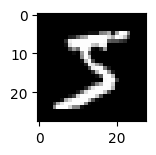

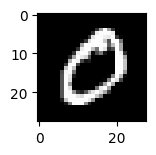

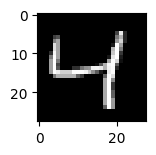

In [ ]:
for i in range(3):  
    pyplot.subplot(330 + 1 + i)
    pyplot.imshow(X_train[i], cmap=pyplot.get_cmap('gray'))
    pyplot.show()

# Usando Keras

In [ ]:
learning_rate = 0.01
num_classes = 10
input_shape = (28, 28)

In [ ]:
# Normalizar y aplanar
X_train_flat = X_train.reshape(-1, 28*28).astype("float32")
X_test_flat  = X_test.reshape(-1, 28*28).astype("float32")

print(X_train_flat.shape, X_test_flat.shape)  # (60000, 784) (10000, 784)

num_features = X_train_flat.shape[1]  # 784

(60000, 784) (10000, 784)


In [ ]:
K.clear_session()
print("Building MNIST model...")

model = Sequential()
model.add(Dense(num_classes,
                activation='softmax',
                input_shape=(num_features,)))

model.compile(
    loss='sparse_categorical_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)

model.summary()

Building MNIST model...


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 10)             │         7,850 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,850 (30.66 KB)

 Trainable params: 7,850 (30.66 KB)

 Non-trainable params: 0 (0.00 B)

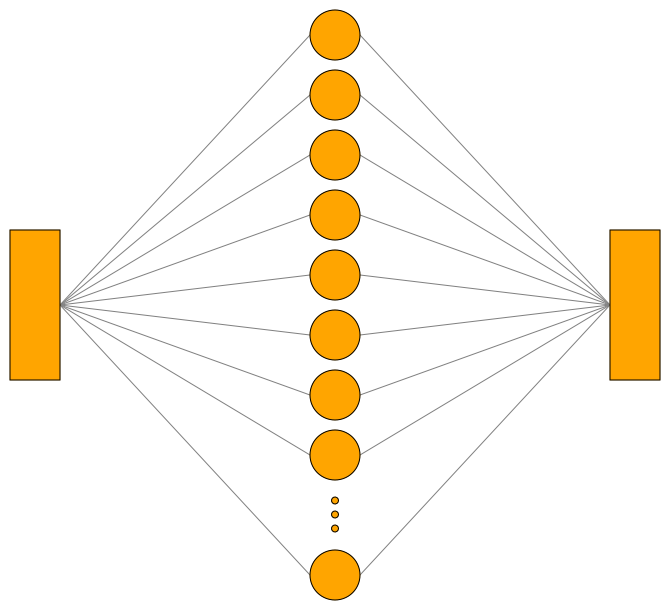

In [ ]:
graph_img = visualkeras.graph_view(
    model,
)

graph_img.save("mnist_graph.png")
Image("mnist_graph.png")

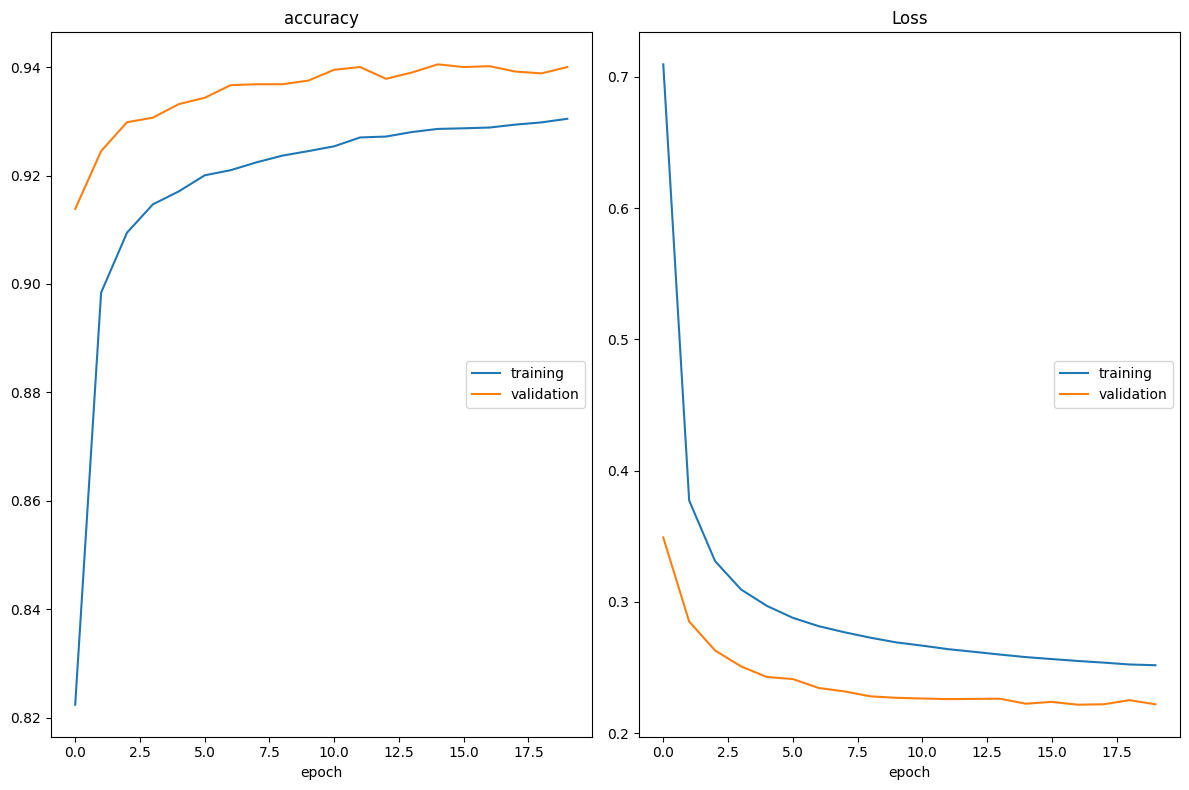

accuracy
	training         	 (min:    0.822, max:    0.930, cur:    0.930)
	validation       	 (min:    0.914, max:    0.941, cur:    0.940)
Loss
	training         	 (min:    0.252, max:    0.710, cur:    0.252)
	validation       	 (min:    0.222, max:    0.349, cur:    0.222)
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9305 - loss: 0.2517 - val_accuracy: 0.9400 - val_loss: 0.2219


In [ ]:
history = model.fit(
    X_train_flat, train_y,
    epochs=20,
    batch_size=128,
    validation_split=0.1,
    verbose=1,
    callbacks=[PlotLossesKeras()]
)

In [ ]:
test_loss, test_acc = model.evaluate(X_test_flat, test_y, verbose=0)
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_acc:.4f}")

Test loss: 1.0252
Test accuracy: 0.8320


In [ ]:
# Predicciones (probabilidades)
y_train_prob = model.predict(X_train_flat)
y_test_prob  = model.predict(X_test_flat)

# Pasar de probabilidades (n,10) a etiquetas (n,)
y_train_pred = np.argmax(y_train_prob, axis=1)
y_test_pred  = np.argmax(y_test_prob, axis=1)

print("=== MÉTRICAS TRAIN ===")
print("Accuracy (train):", accuracy_score(train_y, y_train_pred))

print("\n=== MÉTRICAS TEST ===")
print("Accuracy (test):", accuracy_score(test_y, y_test_pred))

1875/1875 ━━━━━━━━━━━━━━━━━━━━ 2s 843us/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 805us/step
=== MÉTRICAS TRAIN ===
Accuracy (train): 0.81925

=== MÉTRICAS TEST ===
Accuracy (test): 0.832


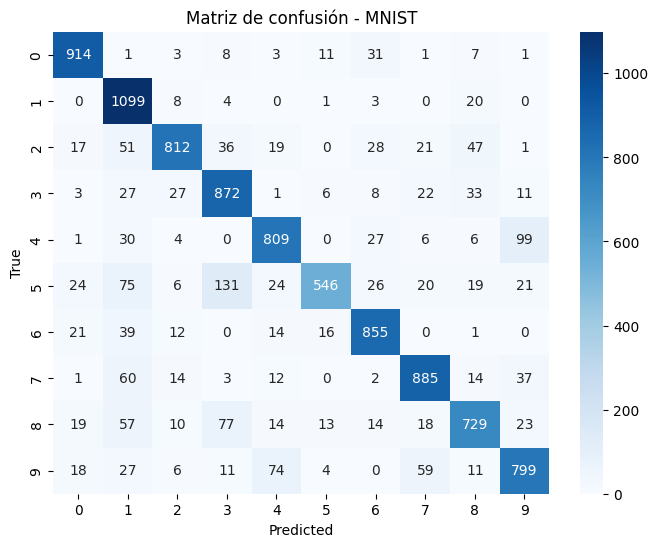


=== Classification report (test) ===
              precision    recall  f1-score   support

           0       0.90      0.93      0.91       980
           1       0.75      0.97      0.85      1135
           2       0.90      0.79      0.84      1032
           3       0.76      0.86      0.81      1010
           4       0.83      0.82      0.83       982
           5       0.91      0.61      0.73       892
           6       0.86      0.89      0.88       958
           7       0.86      0.86      0.86      1028
           8       0.82      0.75      0.78       974
           9       0.81      0.79      0.80      1009

    accuracy                           0.83     10000
   macro avg       0.84      0.83      0.83     10000
weighted avg       0.84      0.83      0.83     10000



In [ ]:
cm = confusion_matrix(test_y, y_test_pred)

plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=range(10),
            yticklabels=range(10))
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Matriz de confusión - MNIST")
plt.show()

print("\n=== Classification report (test) ===")
print(classification_report(test_y, y_test_pred))

In [ ]:
# One-hot de las etiquetas verdaderas
y_test_ohe = to_categorical(test_y, num_classes=num_classes)

# Probabilidades predichas
y_test_prob = model.predict(X_test_flat)

# ROC AUC macro (promedio de las clases)
roc_auc_macro = roc_auc_score(
    y_test_ohe,
    y_test_prob,
    multi_class='ovr',   # one-vs-rest
    average='macro'
)

# ROC AUC micro (considera todas las clases juntas)
roc_auc_micro = roc_auc_score(
    y_test_ohe,
    y_test_prob,
    multi_class='ovr',
    average='micro'
)

print(f"ROC AUC (macro, OVR, test): {roc_auc_macro:.4f}")
print(f"ROC AUC (micro, OVR, test): {roc_auc_micro:.4f}")

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 939us/step
ROC AUC (macro, OVR, test): 0.9787
ROC AUC (micro, OVR, test): 0.9791


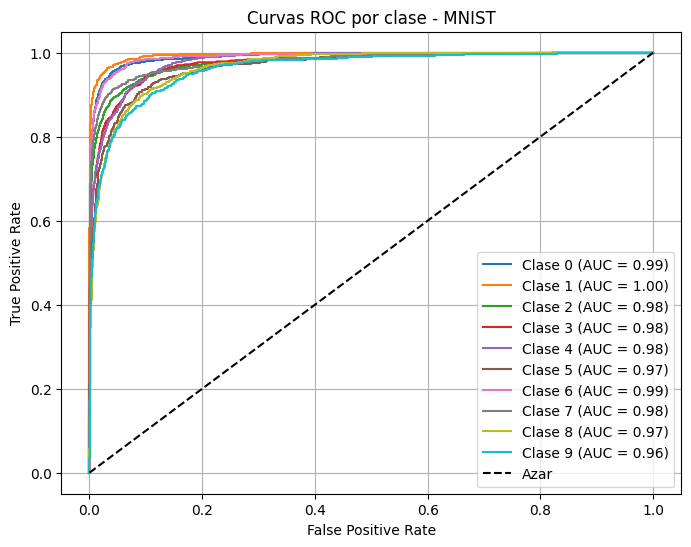

In [ ]:
fpr = {}
tpr = {}
roc_auc = {}

for i in range(num_classes):
    fpr[i], tpr[i], _ = roc_curve(y_test_ohe[:, i], y_test_prob[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

plt.figure(figsize=(8, 6))
for i in range(num_classes):
    plt.plot(fpr[i], tpr[i], label=f'Clase {i} (AUC = {roc_auc[i]:.2f})')

plt.plot([0, 1], [0, 1], 'k--', label='Azar')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Curvas ROC por clase - MNIST')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

### ¿Por qué esta red se parece a una regresión logística?

Piensa en lo que acabamos de hacer con la red neuronal y compáralo con una **regresión logística** clásica 👇

Cuando tenemos una red muy sencilla, del tipo:

- Capa de entrada  
- **Una sola capa densa de salida con activación _softmax_** (para clasificar en varias clases)

en el fondo estamos haciendo **algo muy parecido a una regresión logística multiclase**:

- Cada píxel de la imagen (o cada _feature_ del dataset) tiene un **peso**.  
- La red calcula una **combinación lineal** de esos píxeles.  
- Luego aplica una función _softmax_ para convertir esos valores en probabilidades para cada clase.  

Eso es exactamente la idea de la regresión logística:

> combinación lineal de variables de entrada → función logística/softmax → probabilidad de pertenecer a cada clase.

Si nuestra arquitectura fuera solo:

```text
Entrada (784 features)
   ↓
Dense(10, activation='softmax')
```

estamos prácticamente en el mundo de la regresión logística multiclase.


La llamemos “red neuronal” o “regresión logística”, la capacidad del modelo es lineal: solo puede separar clases si los datos son separables (o razonablemente aproximables) por una frontera lineal en el espacio de características.

## ¿Que funciones de activación tenemos?

Las redes neuronales aprovechan diferentes tipos de funciones de activación para introducir no linealidades y permitir el aprendizaje de patrones complejos. Cada función de activación tiene sus propias propiedades y es adecuada para determinados casos de uso.

Por ejemplo, la función sigmoide es ideal para los problemas de clasificación binaria, softmax es útil para la previsión multiclase y ReLU ayuda a superar el problema de desvanecimiento de gradiente.

### 1) Activación lineal

La función de activación lineal es la función de activación más sencilla, definida como:

$$f(x) = x$$

Simplemente devuelve la entrada $x$ como salida. Gráficamente, es una línea recta con una pendiente de 1.

El principal caso de uso de la función de activación lineal es en la capa de salida de una red neuronal utilizada para la regresión. Para los problemas de regresión en los que queremos prever un valor numérico, utilizar una función de activación lineal en la capa de salida garantiza que la red neuronal produzca un valor numérico. La función de activación lineal no reduce ni transforma la salida, por lo que se devuelve el valor real previsto.

Sin embargo, la función de activación lineal rara vez se utiliza en las capas ocultas de las redes neuronales. Esto se debe a que no proporciona ninguna no linealidad. El objetivo de las capas ocultas es aprender combinaciones no lineales de las características de entrada. Utilizar una activación lineal todo el tiempo restringiría el modelo a aprender solo

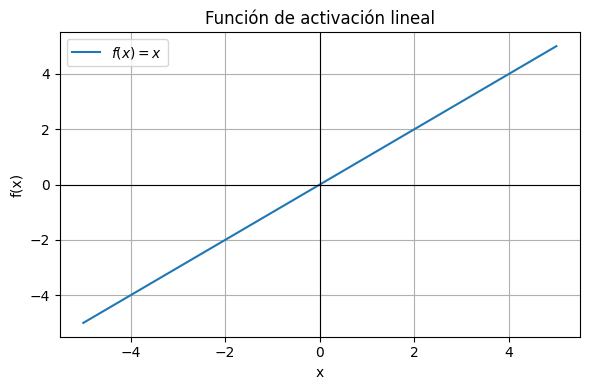

In [ ]:
x = np.linspace(-5, 5, 400)  # desde -5 hasta 5 con 400 puntos
y = x                        # f(x) = x

plt.figure(figsize=(6, 4))
plt.plot(x, y, label=r'$f(x) = x$')

# Ejes y detalles
plt.axhline(0, color='black', linewidth=0.8)
plt.axvline(0, color='black', linewidth=0.8)
plt.xlabel('x')
plt.ylabel('f(x)')
plt.title('Función de activación lineal')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

### 2) Activación Sigmoide

La función de activación sigmoide, a menudo representada como σ(x), es una función infinitamente diferenciable históricamente importante en el desarrollo de las redes neuronales. La función de activación sigmoide tiene la forma matemática:

$$f(x) = 1/(1 + e^{-x})$$

Toma una entrada de valor real y la reduce a un valor entre 0 y 1. La función sigmoide tiene una curva en forma de "S" que tiende a 0 para los números negativos grandes y a 1 para los números positivos grandes. Los resultados pueden interpretarse fácilmente como probabilidades, lo que la hace natural para los problemas de clasificación binaria.

Las unidades sigmoides fueron populares en las primeras redes neuronales, ya que el gradiente es más fuerte cuando la salida de la unidad está cerca de 0,5, lo que permite un entrenamiento eficaz por retropropagación. Sin embargo, las unidades sigmoides sufren el problema de "desvanecimiento de gradiente", que dificulta el aprendizaje en las redes neuronales profundas.

A medida que los valores de entrada se vuelven significativamente positivos o negativos, la función se satura en 0 o 1, con una pendiente extremadamente plana. En estas regiones, el gradiente es muy próximo a cero. Esto da lugar a cambios muy pequeños en los pesos durante la retropropagación, sobre todo para las neuronas de las primeras capas de las redes profundas, lo que hace que el aprendizaje sea penosamente lento o incluso lo detenga. Esto se conoce como el problema de desvanecimiento de gradiente en las redes neuronales.

El principal caso de uso de la función sigmoide es como activación de la capa de salida de los modelos de clasificación binaria. Reduce la salida a un valor de probabilidad entre 0 y 1, que puede interpretarse como la probabilidad de que la entrada pertenezca a una clase determinada.

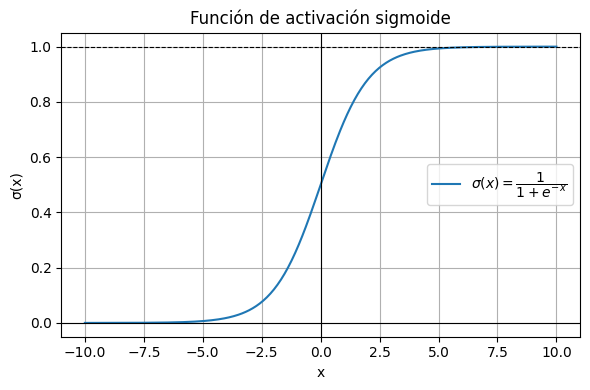

In [ ]:
# Definimos la función sigmoide
def sigmoid(x):
    return 1 / (1 + np.exp(-x))

# Rango de valores para x
x = np.linspace(-10, 10, 400)  # más amplio para ver bien la saturación
y = sigmoid(x)

plt.figure(figsize=(6, 4))
plt.plot(x, y, label=r'$\sigma(x) = \dfrac{1}{1 + e^{-x}}$')

# Ejes y detalles
plt.axhline(0, color='black', linewidth=0.8)
plt.axhline(1, color='black', linewidth=0.8, linestyle='--')
plt.axvline(0, color='black', linewidth=0.8)
plt.xlabel('x')
plt.ylabel('σ(x)')
plt.title('Función de activación sigmoide')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

### 3) Activación Tangente hiperbólica (tanh)

La función de activación de tangente hiperbólica (tanh) se define como:

$$f(x) = \dfrac{(e^x - e^{-x})}{(e^x + e^{- x})}$$

La función tanh produce valores en el intervalo de -1 a +1. Esto significa que puede tratar valores negativos con más eficacia que la función sigmoide, que tiene un intervalo de 0 a 1.

A diferencia de la función sigmoide, tanh está centrada en cero, lo que significa que su resultado es simétrico alrededor del origen del sistema de coordenadas. Esto suele considerarse una ventaja porque puede ayudar a que el algoritmo de aprendizaje converja más rápidamente.

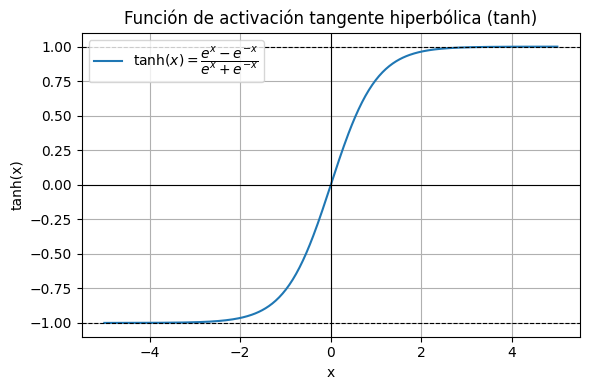

In [ ]:
def tanh(x):
    return np.tanh(x)

# Rango de valores para x
x = np.linspace(-5, 5, 400)
y = tanh(x)

plt.figure(figsize=(6, 4))
plt.plot(x, y, label=r'$\tanh(x) = \dfrac{e^x - e^{-x}}{e^x + e^{-x}}$')

# Ejes y detalles
plt.axhline(0, color='black', linewidth=0.8)
plt.axhline(1, color='black', linewidth=0.8, linestyle='--')
plt.axhline(-1, color='black', linewidth=0.8, linestyle='--')
plt.axvline(0, color='black', linewidth=0.8)
plt.xlabel('x')
plt.ylabel('tanh(x)')
plt.title('Función de activación tangente hiperbólica (tanh)')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

### Activación de unidad lineal rectificada (ReLU)

La función de activación de unidad lineal rectificada (ReLU) tiene la forma:

$$f(x) = max(0, x)$$

Umbraliza la entrada en cero, devolviendo 0 para valores negativos y la propia entrada para valores positivos.

Para entradas mayores que 0, ReLU actúa como una función lineal con un gradiente de 1. Esto significa que no modifica la escala de las entradas positivas y permite que el gradiente pase sin cambios durante la retropropagación. Esta propiedad es fundamental para mitigar el problema de desvanecimiento de gradiente.

Aunque ReLU es lineal para la mitad de su espacio de entrada, técnicamente es una función no lineal porque tiene un punto no diferenciable en x=0, donde cambia bruscamente con respecto a x. Esta no linealidad permite a las redes neuronales aprender patrones complejos

Como ReLU produce cero para todas las entradas negativas, conduce naturalmente a activaciones dispersas; en cualquier momento, solo se activa un subconjunto de neuronas, lo que conduce a una computación más eficiente.

La función ReLU es computacionalmente poco costosa porque implica un simple umbral en cero. Esto permite a las redes escalar a muchas capas sin un aumento significativo de la carga computacional, en comparación con funciones más complejas como la función tanh o la sigmoide.

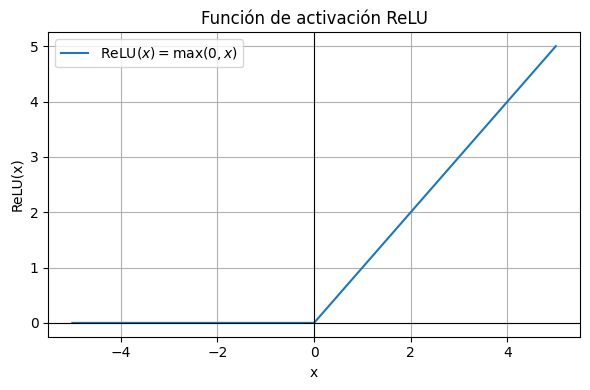

In [ ]:
def relu(x):
    return np.maximum(0, x)

# Rango de valores para x
x = np.linspace(-5, 5, 400)
y = relu(x)

plt.figure(figsize=(6, 4))
plt.plot(x, y, label=r'$\text{ReLU}(x) = \max(0, x)$')

# Ejes y detalles
plt.axhline(0, color='black', linewidth=0.8)
plt.axvline(0, color='black', linewidth=0.8)
plt.xlabel('x')
plt.ylabel('ReLU(x)')
plt.title('Función de activación ReLU')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

### Activación softmax

La función de activación softmax, también conocida como función exponencial normalizada, es especialmente útil en el contexto de los problemas de clasificación multiclase. Esta función opera sobre un vector, a menudo denominado logits, que representa las previsiones o las puntuaciones brutas de cada clase calculadas por las capas anteriores de una red neuronal.

Para un vector de entrada x con elementos x1, x2, ..., xC, la función softmax se define como:

$$f(x_i) = \dfrac{e^{x_i}}{\sum_{j} e^{x_j}}$$

El resultado de la función softmax es una distribución de probabilidad cuya suma es uno. Cada elemento del resultado representa la probabilidad de que la entrada pertenezca a una clase determinada.

El uso de la función exponencial garantiza que todos los valores de salida sean no negativos. Esto es crucial porque las probabilidades no pueden ser negativas.

Softmax amplifica las diferencias en el vector de entrada. Incluso pequeñas diferencias en los valores de entrada pueden dar lugar a diferencias sustanciales en las probabilidades de salida, con los valores de entrada más altos tendiendo a dominar en la distribución de probabilidad resultante.

Softmax se suele utilizar en la capa de salida de una red neuronal cuando la tarea consiste en clasificar una entrada en una de varias (más de dos) categorías posibles (clasificación multiclase).

Las probabilidades producidas por la función softmax pueden interpretarse como puntuaciones de confianza para cada clase, lo que proporciona información sobre la certeza del modelo en cuanto a sus previsiones.

Como softmax amplifica las diferencias, puede ser sensible a los valores atípicos o extremos. Por ejemplo, si el vector de entrada tiene un valor muy grande, softmax puede "reducir" las probabilidades de otras clases, dando lugar a un modelo demasiado confiado.


Imagina que tu red neuronal, en la última capa, saca **un vector de “puntuaciones”** (llamadas *logits*) para cada clase.  
Por ejemplo, para 3 clases:

$$x = [x_1, x_2, x_3] = [2.3,\ -0.7,\ 1.1]$$

Esos números **no son probabilidades**, son solo *scores*:

- pueden ser negativos,  
- no están acotados,  
- no necesariamente suman 1.

La función **softmax** toma ese vector \(x\) y lo convierte en **probabilidades**:

$$\text{softmax}(x_i) \;=\; \frac{e^{x_i}}{\sum_{j=1}^{C} e^{x_j}}$$

Es decir:

- A cada score $x_i$ le aplica una exponencial $e^{x_i}$ → todos los valores quedan positivos.  
- Luego divide cada uno por la **suma total** $\sum_j e^{x_j}$ → así la suma de todos los valores es 1.  

El resultado es un vector como \([0.7, 0.1, 0.2]\) que **sí se puede interpretar como probabilidades**:

- $P(\text{clase 1}) = 0.7$  
- $P(\text{clase 2}) = 0.1$  
- $P(\text{clase 3}) = 0.2$

En resumen:

> Softmax toma un vector de *scores* cualquiera → devuelve un vector de **probabilidades** (todas entre 0 y 1 y que suman 1).

Por eso se usa en la **capa de salida** de redes de **clasificación multiclase** (como el caso de MNIST).

---

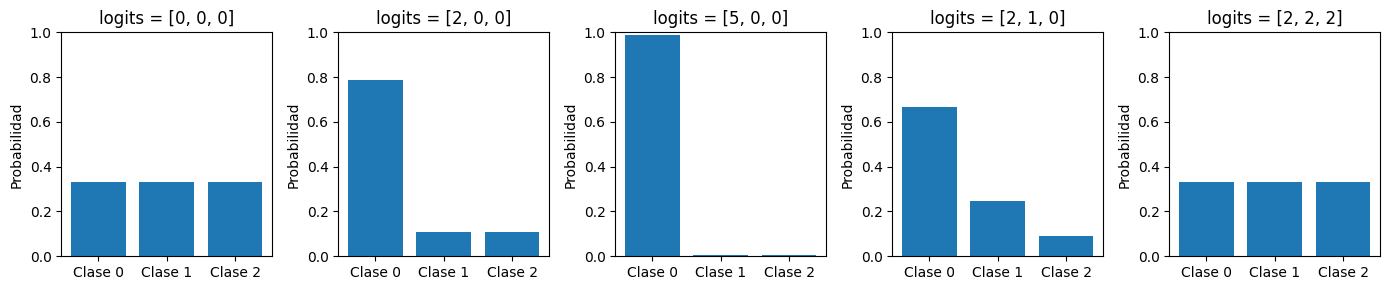

In [ ]:
def softmax(x):
    x = np.array(x)
    e_x = np.exp(x - np.max(x))   # restar el máximo por estabilidad numérica
    return e_x / e_x.sum()

# Algunos ejemplos de logits (3 clases)
logits_list = [
    [0, 0, 0],     # todos iguales
    [2, 0, 0],     # clase 1 un poco mayor
    [5, 0, 0],     # clase 1 mucho mayor
    [2, 1, 0],     # clase 1 algo mayor que las demás
    [2, 2, 2],     # todas iguales pero más grandes
]

titles = [
    "logits = [0, 0, 0]",
    "logits = [2, 0, 0]",
    "logits = [5, 0, 0]",
    "logits = [2, 1, 0]",
    "logits = [2, 2, 2]",
]

num_examples = len(logits_list)
classes = np.arange(3)

plt.figure(figsize=(14, 3))

for i, logits in enumerate(logits_list, start=1):
    probs = softmax(logits)

    plt.subplot(1, num_examples, i)
    plt.bar(classes, probs)
    plt.ylim(0, 1)
    plt.xticks(classes, [f"Clase {c}" for c in classes])
    plt.title(titles[i-1])
    plt.ylabel("Probabilidad")

plt.tight_layout()
plt.show()

## Elección de la función de activación adecuada

La elección de la función de activación depende del tipo de problema que intentes resolver. Aquí tienes algunas pautas:

 - Para la clasificación binaria: Utiliza la función de activación sigmoide en la capa de salida. Reducirá las salidas a un valor entre 0 y 1, que representa las probabilidades de las dos clases.

 - Para la clasificación multiclase: Utiliza la función de activación softmax en la capa de salida. Dará como resultado distribuciones de probabilidad sobre todas las clases.

 - Si no estás seguro: Utiliza la función de activación ReLU en las capas ocultas. ReLU es la función de activación predeterminada más común y suele ser una buena elección.

### ¿Por qué tiene sentido agregar capas internas?

La verdadera “magia” de las redes neuronales aparece cuando agregamos capas ocultas con activaciones no lineales (ReLU, tanh, etc.):


Entrada (784)

   ↓

Dense(128, relu)

   ↓

Dense(64, relu)

   ↓

Dense(10, softmax)

### ¿Qué ganamos con eso?

Más capacidad de representación
Las capas ocultas permiten construir combinaciones no lineales de los píxeles.
La red ya no aprende solo “fronteras rectas”, sino fronteras de decisión mucho más complejas.

## Aprendizaje de características

En vez de pedirle al modelo que decida directamente “¿es un 3 o un 8?” a partir de los píxeles crudos, las capas internas pueden aprender representaciones intermedias:

bordes,

trazos,

curvas…

Es como si la red fabricara sus propios “features” antes de tomar la decisión final.

### Separar mejor clases difíciles

Algunos dígitos son muy parecidos entre sí (por ejemplo, 4 y 9, o 3 y 5).
Una frontera lineal puede quedarse corta; en cambio, una red con capas ocultas puede aprender superficies de decisión más ricas para separar esos casos difíciles.


## Multi-Layer Fully Connected Networks

La idea de crear una arquitectura compleja, surge de permitirle a la red poder "ensamblar" las distintas partes de la imagen identificando internamente patrones que caracterizan a cada número, o al menos eso es lo que queremos creer en términos de ampliar la estructura de la red

<img src="MLP.png" width="600px">

O de una forma más gráfica esperamos que la red identifique los números:

<img src="Multilayer_numbers.png" width="800px">

<img src="Multilayer_arch.png" width="800px">

Este principio se vuelve realmente útil al momento de reconocer imágenes, ya que las redes neuronales tienen la capacidad de aprender de patrones complejos, de ahí su utilidad en reconocimiento de imágenes, procesamiento de lenguaje natural o incluso análisis de audio.


In [ ]:
K.clear_session()
print("Building MNIST model...")

model = Sequential()

# Capa de entrada (solo especificamos la forma)
model.add(Input(shape=(num_features,)))

# Capas ocultas con activación no lineal
#model.add(Dense(128, activation='tanh'))
model.add(Dense(64, activation='sigmoid'))
model.add(Dense(64, activation='relu'))

# Capa de salida con softmax (clasificación multiclase)
model.add(Dense(num_classes, activation='softmax'))

model.compile(
    loss='sparse_categorical_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)

model.summary()

Building MNIST model...


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │        50,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 55,050 (215.04 KB)

 Trainable params: 55,050 (215.04 KB)

 Non-trainable params: 0 (0.00 B)

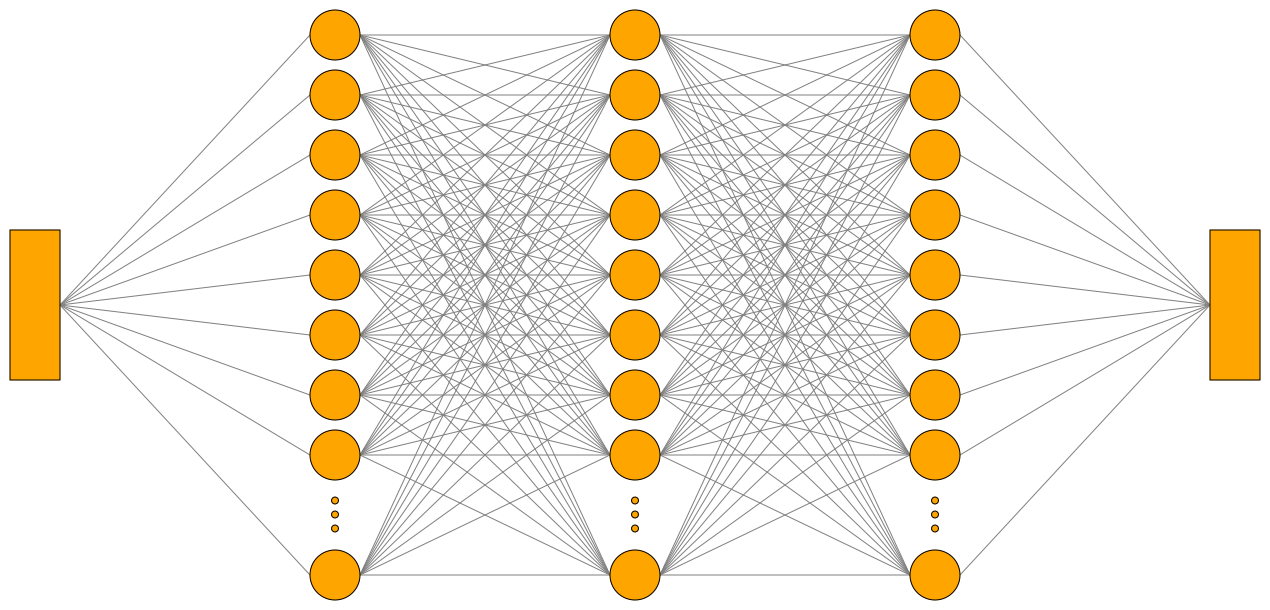

In [ ]:
graph_img = visualkeras.graph_view(
    model,
)

graph_img.save("mnist_deep_graph.png")
Image("mnist_deep_graph.png")

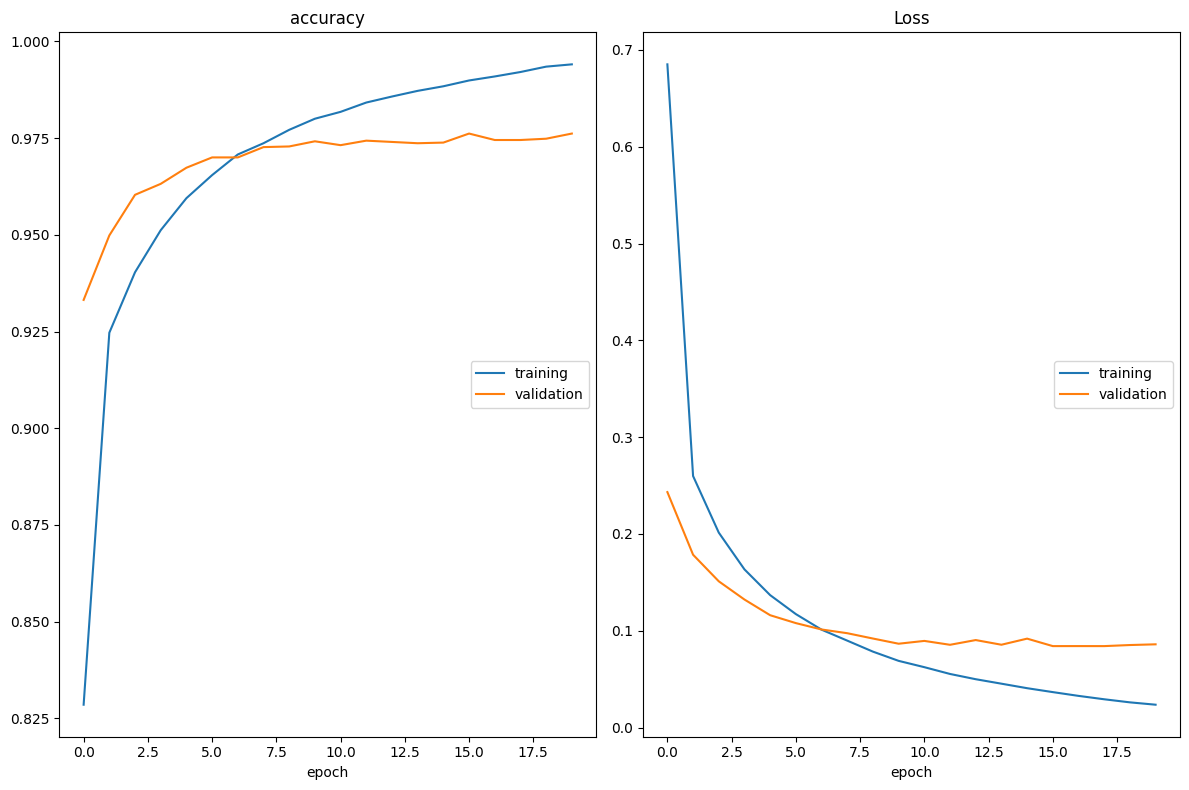

accuracy
	training         	 (min:    0.829, max:    0.994, cur:    0.994)
	validation       	 (min:    0.933, max:    0.976, cur:    0.976)
Loss
	training         	 (min:    0.024, max:    0.685, cur:    0.024)
	validation       	 (min:    0.084, max:    0.243, cur:    0.086)


In [ ]:
history = model.fit(
    X_train_flat, train_y,
    epochs=20,
    batch_size=128,
    validation_split=0.1,
    verbose=0,                 # para que no imprima por consola
    callbacks=[PlotLossesKeras()]
)

In [ ]:
# Predicciones (probabilidades)
y_train_prob = model.predict(X_train_flat)
y_test_prob  = model.predict(X_test_flat)

# Pasar de probabilidades (n,10) a etiquetas (n,)
y_train_pred = np.argmax(y_train_prob, axis=1)
y_test_pred  = np.argmax(y_test_prob, axis=1)

print("=== MÉTRICAS TRAIN ===")
print("Accuracy (train):", accuracy_score(train_y, y_train_pred))

print("\n=== MÉTRICAS TEST ===")
print("Accuracy (test):", accuracy_score(test_y, y_test_pred))

1875/1875 ━━━━━━━━━━━━━━━━━━━━ 2s 824us/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step  
=== MÉTRICAS TRAIN ===
Accuracy (train): 0.9940833333333333

=== MÉTRICAS TEST ===
Accuracy (test): 0.9746


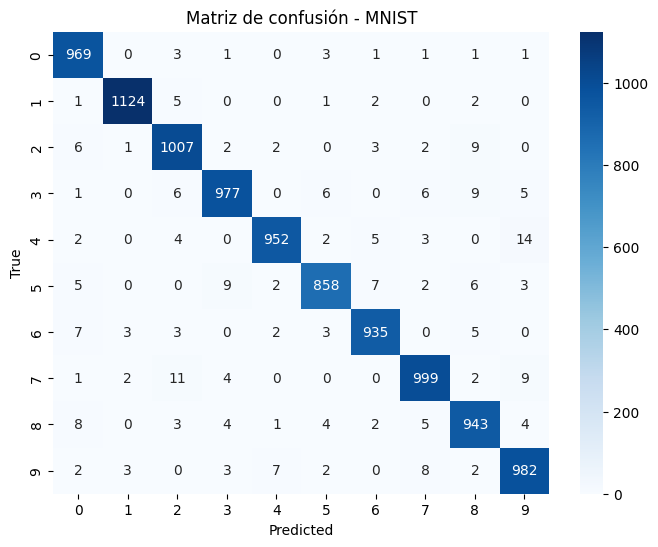


=== Classification report (test) ===
              precision    recall  f1-score   support

           0       0.97      0.99      0.98       980
           1       0.99      0.99      0.99      1135
           2       0.97      0.98      0.97      1032
           3       0.98      0.97      0.97      1010
           4       0.99      0.97      0.98       982
           5       0.98      0.96      0.97       892
           6       0.98      0.98      0.98       958
           7       0.97      0.97      0.97      1028
           8       0.96      0.97      0.97       974
           9       0.96      0.97      0.97      1009

    accuracy                           0.97     10000
   macro avg       0.97      0.97      0.97     10000
weighted avg       0.97      0.97      0.97     10000



In [ ]:
cm = confusion_matrix(test_y, y_test_pred)

plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=range(10),
            yticklabels=range(10))
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Matriz de confusión - MNIST")
plt.show()

print("\n=== Classification report (test) ===")
print(classification_report(test_y, y_test_pred))

In [ ]:
# One-hot de las etiquetas verdaderas
y_test_ohe = to_categorical(test_y, num_classes=num_classes)

# Probabilidades predichas
y_test_prob = model.predict(X_test_flat)

# ROC AUC macro (promedio de las clases)
roc_auc_macro = roc_auc_score(
    y_test_ohe,
    y_test_prob,
    multi_class='ovr',   # one-vs-rest
    average='macro'
)

# ROC AUC micro (considera todas las clases juntas)
roc_auc_micro = roc_auc_score(
    y_test_ohe,
    y_test_prob,
    multi_class='ovr',
    average='micro'
)

print(f"ROC AUC (macro, OVR, test): {roc_auc_macro:.4f}")
print(f"ROC AUC (micro, OVR, test): {roc_auc_micro:.4f}")

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 922us/step
ROC AUC (macro, OVR, test): 0.9995
ROC AUC (micro, OVR, test): 0.9995


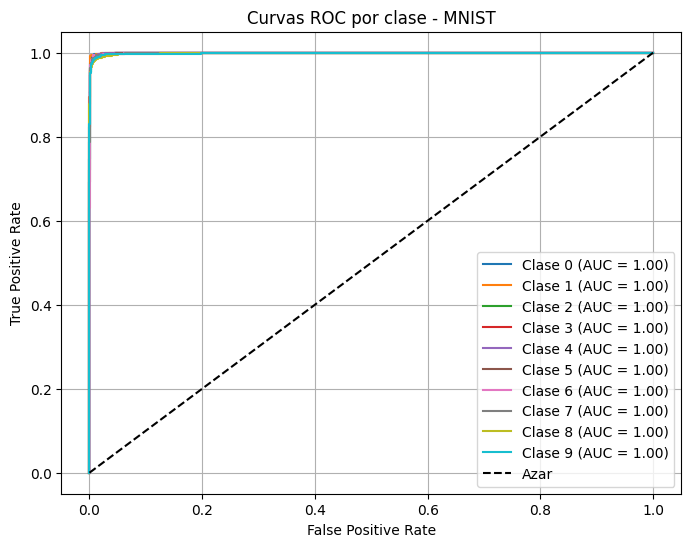

In [ ]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

fpr = {}
tpr = {}
roc_auc = {}

for i in range(num_classes):
    fpr[i], tpr[i], _ = roc_curve(y_test_ohe[:, i], y_test_prob[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

plt.figure(figsize=(8, 6))
for i in range(num_classes):
    plt.plot(fpr[i], tpr[i], label=f'Clase {i} (AUC = {roc_auc[i]:.2f})')

plt.plot([0, 1], [0, 1], 'k--', label='Azar')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Curvas ROC por clase - MNIST')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

## Tipos de redes neuronales 🧠

Hay varios tipos de redes neuronales que cumplen diferentes funciones en las aplicaciones de ciberseguridad:

### Tabla resumen de tipos de redes neuronales en Ciberseguridad

| Tipo de red neuronal                    | Características principales                                                                 | Aplicaciones principales en Ciberseguridad                                                                                     | Puntos fuertes                                                                                                      |
|----------------------------------------|---------------------------------------------------------------------------------------------|-------------------------------------------------------------------------------------------------------------------------------|---------------------------------------------------------------------------------------------------------------------|
| **Alimentación directa (FNN)**         | Flujo de información unidireccional, arquitectura más simple                               | Clasificación de malware, evaluación de vulnerabilidades y detección de amenazas binarias.                                   | Procesamiento rápido, fácil implementación y fiable para la clasificación básica.                                   |
| **Convolucional (CNN)**                | Capas especializadas para el reconocimiento de patrones, procesamiento basado en filtros   | Análisis de tráfico, visualización de malware, análisis binario, detección de amenazas basada en imágenes.                   | Excelente reconocimiento de patrones, maneja estructuras de datos complejas y tiene una alta precisión.            |
| **Recurrente (RNN)**                   | Memoria de entradas anteriores, procesamiento secuencial de datos                          | Análisis del comportamiento de los usuarios, detección de ataques secuenciales y análisis de registros a lo largo del tiempo.| Reconocimiento de patrones temporales, consciencia contextual y aprendizaje secuencial.                            |
| **Memoria a corto plazo larga (LSTM)** | Mejora la memoria a largo plazo, resuelve el problema del gradiente desaparecido          | Detección de APT, análisis de cadenas de ataques complejos y monitoreo de amenazas ampliado.                                 | Modela dependencias a largo plazo, secuencias complejas y permite seguimiento persistente de amenazas.             |
| **Red neuronal gráfica (GNN)**         | Procesa datos estructurados en grafos, análisis de relaciones                              | Análisis de la topología de la red, mapeo de la propagación de ataques y detección de movimientos laterales.                 | Modelado de relaciones, visibilidad en toda la red y detección sensible al contexto.                               |
| **Redes generativas adversarias (GAN)**| Arquitectura generador–discriminador, entrenamiento adversarial                            | Simulación de amenazas, pruebas de penetración, detección de anomalías y generación de datos sintéticos.                     | Crea escenarios realistas, enriquece los datos de entrenamiento y aumenta la robustez de los sistemas de detección.|
| **Redes de funciones de base radial (RBFN)** | Funciones de activación basadas en la distancia, respuestas localizadas               | Detección de anomalías en series temporales, análisis predictivo de seguridad y supervisión del rendimiento.                 | Modelado local preciso, entrenamiento rápido y eficaz para tipos específicos de anomalías.                         |

---

## Aplicaciones de las redes neuronales 🌐

Las redes neuronales transforman múltiples industrias gracias a su versatilidad. Algunas aplicaciones clave incluyen:

- **Reconocimiento de imágenes:**  
  Identificación de objetos en fotos, por ejemplo, sistemas como Google Fotos.

- **Procesamiento del habla:**  
  Impulsan asistentes de voz (Siri, Alexa) con capacidades de transcripción y comprensión en tiempo real.

- **Procesamiento del lenguaje natural (NLP):**  
  Alimentan chatbots, sistemas de resumen automático de texto y herramientas de traducción automática.

- **Sistemas autónomos:**  
  Guiado de vehículos autónomos mediante el análisis de datos de sensores (cámaras, LIDAR, radar, etc.).

- **Cuidado de la salud:**  
  Detección precisa de tumores y otras patologías en imágenes médicas como resonancias magnéticas o rayos X.

- **Finanzas:**  
  Predicción de movimientos del mercado, detección de fraude y optimización de carteras con mínima latencia.

La potencia de las redes neuronales se deriva de su capacidad para adaptarse a **conjuntos de datos diversos y complejos**, aprendiendo representaciones que mejoran el desempeño en tareas de clasificación, regresión, detección de anomalías y más.
